<a href="https://colab.research.google.com/github/Michael-M-Maciel/DIO_Bradesco_Agent_AI_Projeto_deteccao_fraude_cartao/blob/main/DIO_Bradesco_agenteIA_do_zero_Detec%C3%A7%C3%A3o_de_Anomalias_em_Transa%C3%A7%C3%B5es_em_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# importando o pandas
import pandas as pd

# link data set
url ='https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'

#criando data frame(tabela) com dados recebidos
df = pd.read_csv(url)

#lendo a tabela
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Medição de proporção de fraudes e desbalanceamento

In [12]:
#Contar o total absoluto de transações normais(0) e fraudes (1)
contagem_absoluta = df['Class'].value_counts() #conta o numero de 0(normal) e 1(fraude) existem na tabela
print('Quantidade de transações')
print(contagem_absoluta)

print('\n-----------------------\n')

# Contar a proporção (percemtagem em decimal) de cada classe
proporcao = df['Class'].value_counts(normalize=True)
print('Proporção de transação')
print(proporcao)

Quantidade de transações
Class
0    284315
1       492
Name: count, dtype: int64

-----------------------

Proporção de transação
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


Preparação dos dados

In [16]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Instanciar o padronizador
scaler = StandardScaler()

# 2. Criar uma nova coluna com o log do valor (log1p evita erros com iguais a zero)
df['Log_Amount'] = np.log1p(df['Amount'])

# 3. Padronizar o tempo e o Log do Valor.
#o reshape(-1, 1) é nececssario por que o StandarScaler exige os dados  num formato de matriz (coluna vertical)
df['Scaled_Time'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))
df['Scaled_Amount'] = scaler.fit_transform(df['Log_Amount'].values.reshape(-1, 1))

# 4. Apagar as colunas originais que já não precisamos
df = df.drop(['Time', 'Amount', 'Log_Amount'], axis=1)

# Mostrar as primeiras linhas para confirmar a alteração
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,Class,Scaled_Time,Scaled_Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,-1.996583,1.124303
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-1.996583,-1.114639
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,-1.996562,1.682368
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,-1.996562,1.009339
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-1.996541,0.670241


In [17]:
from sklearn.model_selection import train_test_split

# 1. Separar as pistas (X) do nosso alvo (y)
X = df.drop('Class', axis=1) # O X é a tabela toda, menos a coluna Class
y = df['Class']              # O y é apenas a coluna Class (se é fraude ou não)

# 2. Dividir em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,     # 20% para teste
    random_state=42,    # Garante que a divisão aleatória será sempre igual se rodarmos de novo
    stratify=y          # Mantém a mesma proporção de fraudes no treino e no teste
)

# 3. Mostrar o resultado
print(f"Linhas para Treino: {X_train.shape[0]}")
print(f"Linhas para Teste: {X_test.shape[0]}")

Linhas para Treino: 227845
Linhas para Teste: 56962


In [18]:
from sklearn.linear_model import LogisticRegression

# 1. Criar o modelo (o "aluno") com o ajuste de peso para as fraudes
modelo_lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

# 2. Treinar o modelo com as pistas e respostas (O aluno vai estudar)
modelo_lr.fit(X_train, y_train)

# 3. Pedir ao modelo para prever as fraudes nos dados que ele nunca viu (A prova final)
previsoes_lr = modelo_lr.predict(X_test)

print("Treino concluído e previsões geradas com sucesso!")

Treino concluído e previsões geradas com sucesso!


In [19]:
from sklearn.metrics import classification_report

# Gerar o relatório comparando as respostas reais (y_test) com os palpites do modelo (previsoes_lr)
relatorio = classification_report(y_test, previsoes_lr)

print("Relatório de Classificação da Regressão Logística:\n")
print(relatorio)

Relatório de Classificação da Regressão Logística:

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



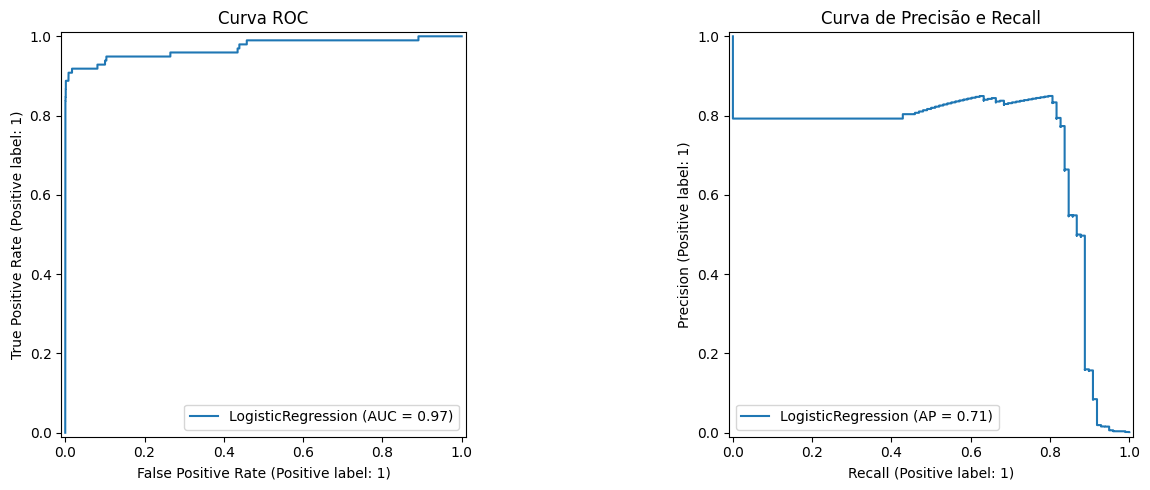

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Criar um espaço visual com duas áreas lado a lado (1 linha, 2 colunas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gerar e desenhar a Curva ROC na primeira área (ax1)
RocCurveDisplay.from_estimator(modelo_lr, X_test, y_test, ax=ax1)
ax1.set_title("Curva ROC")

# 2. Gerar e desenhar a Curva de Precisão-Recall na segunda área (ax2)
PrecisionRecallDisplay.from_estimator(modelo_lr, X_test, y_test, ax=ax2)
ax2.set_title("Curva de Precisão e Recall")

# Ajustar os espaços e mostrar a imagem final no ecrã
plt.tight_layout()
plt.show()

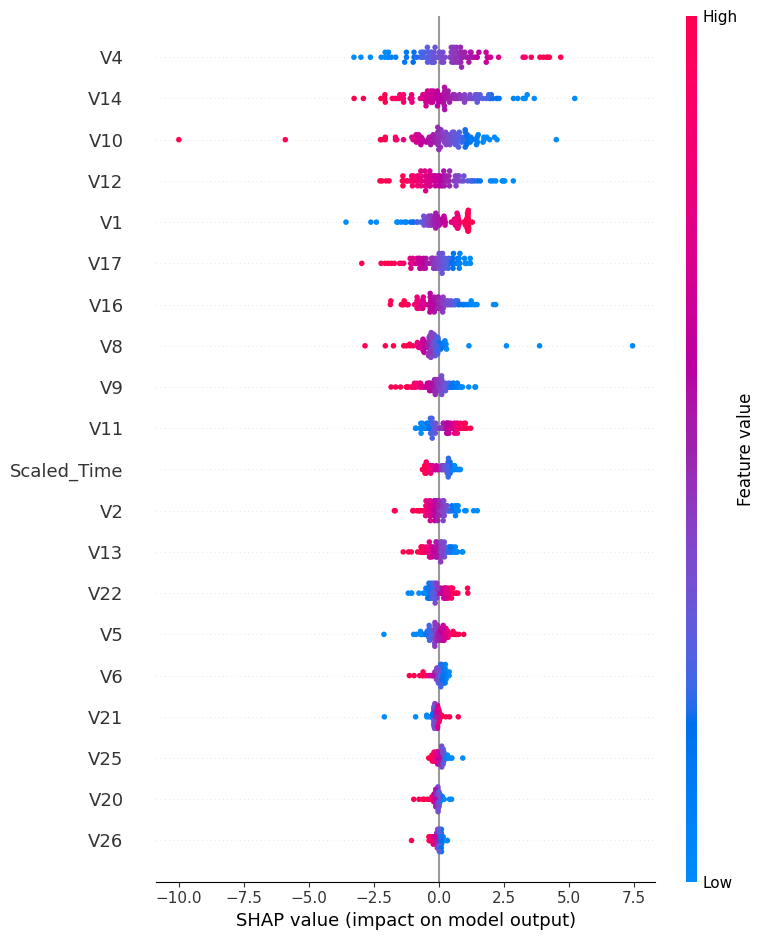

In [21]:
# 1. Instalar a biblioteca (o ponto de exclamação roda o comando no sistema do Colab)
!pip install shap

import shap
import matplotlib.pyplot as plt

# 2. Criar o explicador conectando-o ao nosso modelo e aos dados de treino
explicador = shap.LinearExplainer(modelo_lr, X_train)

# 3. Separar uma pequena amostra de 100 transações de teste para o cálculo ser rápido
amostra_teste = X_test.iloc[:100]

# 4. Calcular a "culpa" de cada variável nessas 100 transações
valores_shap = explicador.shap_values(amostra_teste)

# 5. Desenhar o gráfico de impacto
shap.summary_plot(valores_shap, amostra_teste)